In [1]:
from visualize import *
from data_generation import *   
from preprocessing import *
from sb import loss
from sb import model
from datasets.dataset import *
from torch.utils.data import DataLoader

In [ ]:
high_resol_coef = 0.01 # 점성 계수 작게
low_resol_coef = 0.02 # 점성 계수 크게

high_f_1d = generate_dataset(
    n_samples=1,
    nu=high_resol_coef,    
    Nx=128,    
    Nt=256, 
    T=1.0,
    L=1.0,
    seed=0,
)
low_f_1d = generate_dataset(
    n_samples=1,
    nu=low_resol_coef,    
    Nx=128,    
    Nt=256, 
    T=1.0,
    L=1.0,
    seed=20,
)

100%|██████████| 1/1 [00:00<00:00, 97.87it/s]


In [ ]:
WA, WB, starts = make_paired_time_window_dataset(
    data1, # full grid 줄 친구
    data2, # 일부 센서만 줄 친구
    win_T=128,
    stride=128,
    start_t=0,
    end_t=None,
)

In [ ]:
# # 코드 작성을 위해 임의로 만든 샘플 데이터임. 추후 시뮬 데이터로 교체 예정
# high = np.load("./data_test/NS-Re1000_T255.npy", mmap_mode="r")
# high_f_2d = np.concatenate([high] * 10, axis=0)

# low = np.load("./data_test/NS-Re1000_T255.npy", mmap_mode="r")
# low_f_2d = np.concatenate([low] * 10, axis=0)

In [ ]:
mask_high_1d = make_sensor_mask(high_f_1d, n_sensors=13, sparse_ratio=None, seed=0)
mask_low_1d = make_sensor_mask(low_f_1d, n_sensors=13, sparse_ratio=None, seed=0)

# mask_high_2d = make_sensor_mask(high_f_2d, n_sensors=int(256*256*0.1), sparse_ratio=None, seed=0)
# mask_low_2d = make_sensor_mask(low_f_2d, n_sensors=int(256*256*0.1), sparse_ratio=None, seed=0)

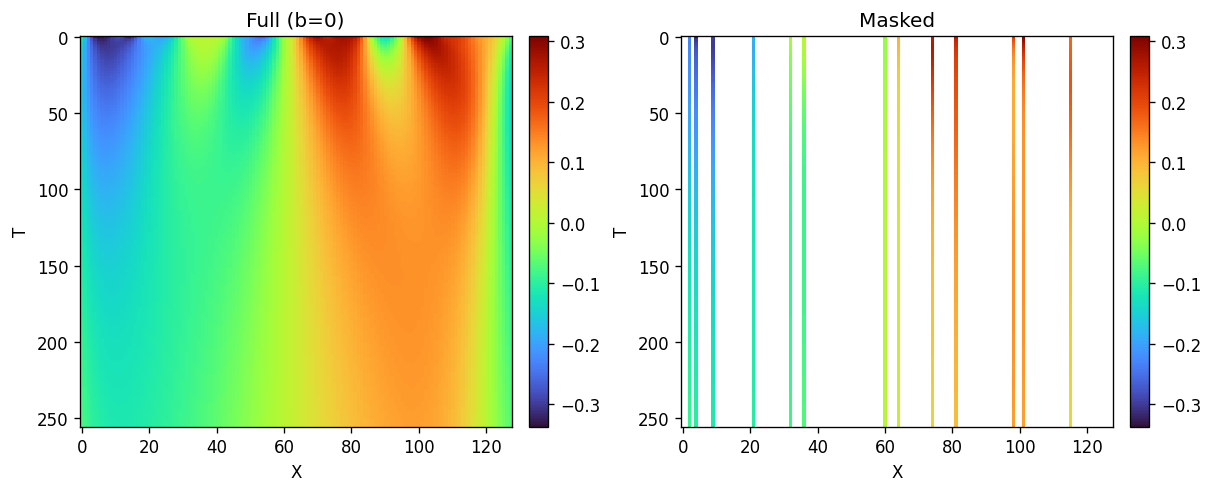

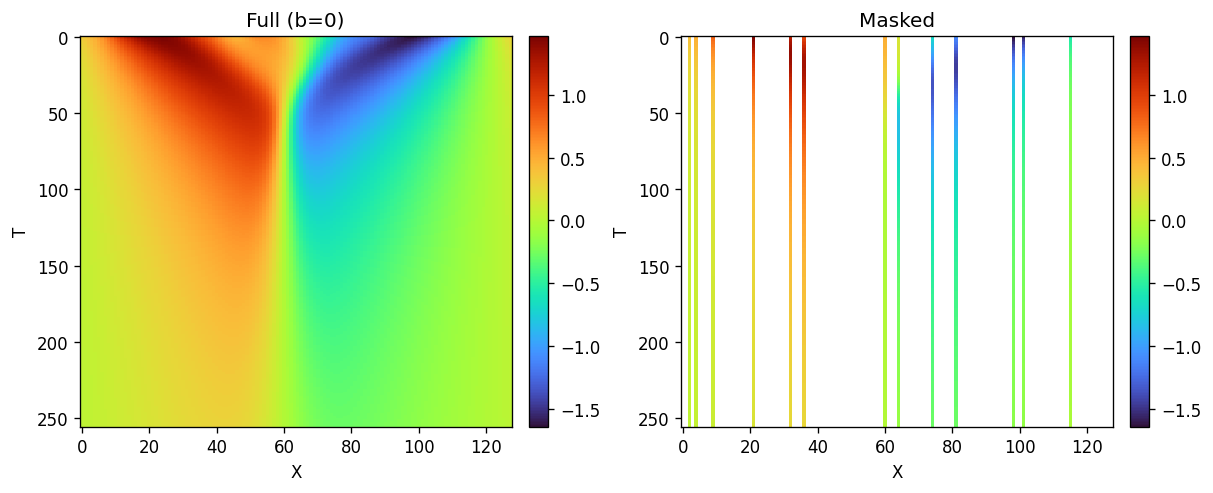

In [ ]:
# dataset_visualization(high_f_1d, mask_high_1d, batch_idx=0)
# dataset_visualization(low_f_1d, mask_low_1d, batch_idx=0)

In [7]:
ds_1d = PDEPairDataset(low_f_1d, high_f_1d, None, mask_high_1d)
dl_1d = DataLoader(ds_1d, batch_size=2, shuffle=True, drop_last=False)

ds_2d = PDEPairDataset(low_f_2d, high_f_2d, None, mask_high_2d)
dl_2d = DataLoader(ds_2d, batch_size=2, shuffle=True, drop_last=False)

In [8]:
steps = 10
sb_object = model.SB_model_ver1(dl_1d, [0,1], time_dim=8, steps=steps, base_lr=1e-3, save=True, pde_type='burgers')

In [9]:
sb_object.train(train_epochs=10)

Train (1 batch per epoch): 100%|██████████| 10/10 [00:02<00:00,  4.26it/s]


In [10]:
batch = next(iter(dl_1d))
x_0, x_1, mask_low, mask_high = batch

pred_last = sb_object.eval_fore(
    x_0=x_0,
    x_1=x_1,        
    mask_low=mask_low,
    mask_high=mask_high
)

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_prediction(x_0, x_1, pred, mask=None, batch_idx=0, cmap="turbo"):
    """
    x_0, x_1, pred:
      1D -> (B,1,T,X)
      2D -> (B,T,X,Y)
    mask:
      동일 shape의 bool mask (없으면 None)
    """
    x0 = x_0[batch_idx].detach().cpu().numpy()
    x1 = x_1[batch_idx].detach().cpu().numpy()
    xp = pred[batch_idx].detach().cpu().numpy()
    m  = None if mask is None else mask[batch_idx].detach().cpu().numpy()

    # ---------- 1D ----------
    if x0.ndim == 3:  # (1,T,X)
        x0 = x0[0]
        x1 = x1[0]
        xp = xp[0]
        if m is not None:
            m = m[0]

        fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)

        vmin = min(x0.min(), x1.min())
        vmax = max(x0.max(), x1.max())

        axes[0].imshow(x0, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
        axes[0].set_title("x₀ (input)")

        if m is not None:
            x1_masked = np.ma.masked_where(~m, x1)
            axes[1].imshow(x1_masked, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
            axes[1].set_title("x₁ (observed)")
        else:
            axes[1].imshow(x1, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
            axes[1].set_title("x₁ (target)")

        axes[2].imshow(xp, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
        axes[2].set_title("prediction")

        for ax in axes:
            ax.set_xlabel("x")
            ax.set_ylabel("t")

        plt.show()
        return

    # ---------- 2D ----------
    # (T,X,Y)
    T = x0.shape[0]
    t_idxs = [0, T // 2, T - 1]

    fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)

    for col, t in enumerate(t_idxs):
        vmin = min(x0[t].min(), x1[t].min())
        vmax = max(x0[t].max(), x1[t].max())

        axes[0, col].imshow(xp[t], cmap=cmap, vmin=vmin, vmax=vmax)
        axes[0, col].set_title(f"pred (t={t})")

        if m is not None:
            obs = np.ma.masked_where(~m[t], x1[t])
            axes[1, col].imshow(obs, cmap=cmap, vmin=vmin, vmax=vmax)
            axes[1, col].set_title(f"observed (t={t})")
        else:
            axes[1, col].imshow(x1[t], cmap=cmap, vmin=vmin, vmax=vmax)
            axes[1, col].set_title(f"x₁ (t={t})")

        axes[0, col].axis("off")
        axes[1, col].axis("off")

    plt.show()


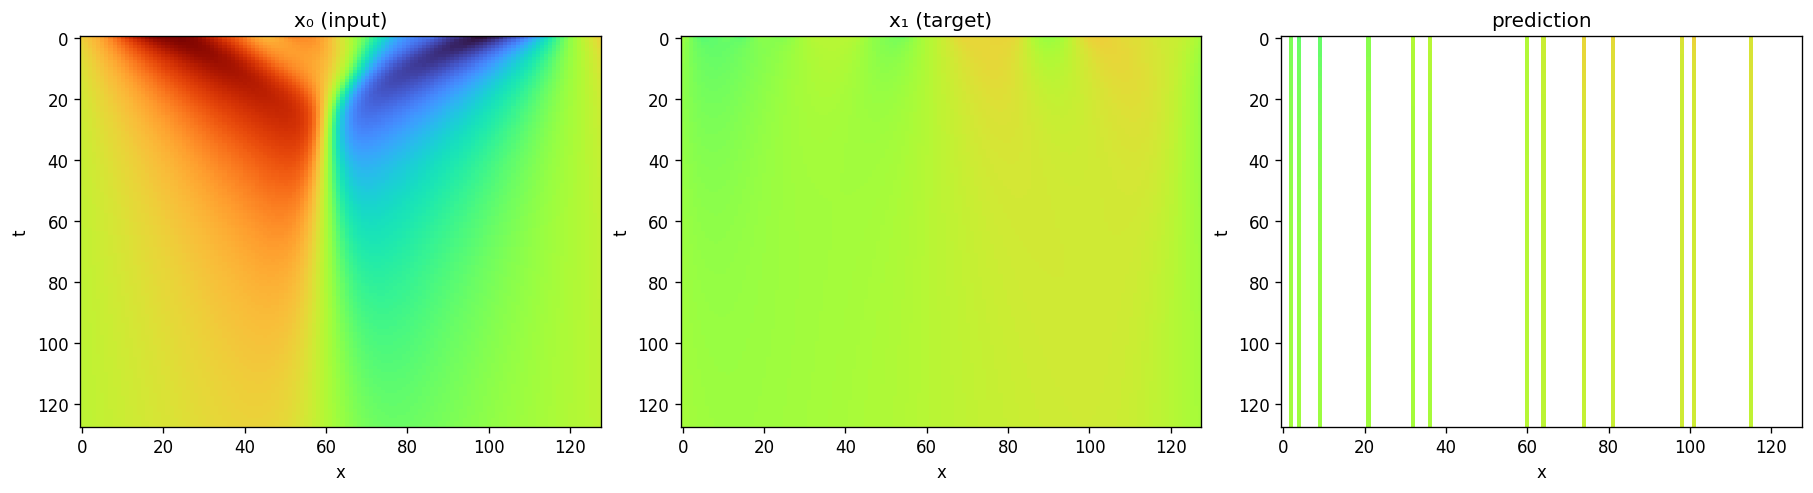

In [11]:
visualize_prediction(
    x_0=x_0,
    x_1=x_1,
    pred=pred_last[-1],
    mask=None,     # 없으면 None
    batch_idx=0
)
